# Siêu phẳng phân chia và khoảng cách tới siêu phẳng

*Bài 7, mục 7.1.1.* Siêu phẳng trong $\mathbb{R}^d$: $\mathbf{w}^T\mathbf{x} + b = 0$, vector $\mathbf{w}$ vuông góc với siêu phẳng. Khoảng cách có dấu từ điểm $\mathbf{x}_i$ có nhãn $y_i \in \{-1, +1\}$ tới siêu phẳng:
$$d_i = \frac{y_i(\mathbf{w}^T\mathbf{x}_i + b)}{\|\mathbf{w}\|_2}$$
$d_i > 0$ nghĩa là điểm nằm đúng phía. Lề (margin) của siêu phẳng là khoảng cách nhỏ nhất $\gamma = \min_i d_i$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Dữ liệu ví dụ 8 điểm, nhãn y thuộc {+1, -1}
X = np.array([[3, 1], [3, -1], [6, 1], [6, -1],      # lớp +1
              [1, 0], [0, 1], [0, -1], [-1, 0]], dtype=float)   # lớp -1
y = np.array([1, 1, 1, 1, -1, -1, -1, -1])


def signed_distance(w, b, X, y):
    """Khoảng cách có dấu d_i = y_i (w^T x_i + b) / ||w||."""
    return y * (X @ w + b) / np.linalg.norm(w)


def margin(w, b, X, y):
    """Lề gamma = min_i d_i (âm nếu có điểm bị phân loại sai)."""
    return signed_distance(w, b, X, y).min()

## 1. Phân loại bằng dấu của $\mathbf{w}^T\mathbf{x} + b$

Xét siêu phẳng $x_1 - 2 = 0$, tức $\mathbf{w} = (1, 0)$, $b = -2$.

In [2]:
w, b = np.array([1.0, 0.0]), -2.0
scores = X @ w + b                       # giá trị w^T x + b
print('w^T x + b :', scores)
print('Dự đoán   :', np.sign(scores).astype(int))
print('Nhãn thật :', y)
print('Khoảng cách có dấu:', signed_distance(w, b, X, y))
print('Lề gamma = %.3f' % margin(w, b, X, y))

w^T x + b : [ 1.  1.  4.  4. -1. -2. -2. -3.]
Dự đoán   : [ 1  1  1  1 -1 -1 -1 -1]
Nhãn thật : [ 1  1  1  1 -1 -1 -1 -1]
Khoảng cách có dấu: [1. 1. 4. 4. 1. 2. 2. 3.]
Lề gamma = 1.000


## 2. Nhân $\mathbf{w}, b$ với $k > 0$ không đổi siêu phẳng, không đổi khoảng cách

Giá trị $\mathbf{w}^T\mathbf{x} + b$ thay đổi theo $k$ nhưng khoảng cách hình học thì không. Đây là cơ sở để chuẩn hóa sao cho các điểm gần nhất thỏa $y_i(\mathbf{w}^T\mathbf{x}_i + b) = 1$ (mục 7.1.2).

In [3]:
for k in [1, 2, 0.5]:
    print('k = %-4s w^T x + b của điểm (3, 1) = %5.2f,  lề = %.3f'
          % (k, (k * w) @ X[0] + k * b, margin(k * w, k * b, X, y)))

k = 1    w^T x + b của điểm (3, 1) =  1.00,  lề = 1.000
k = 2    w^T x + b của điểm (3, 1) =  2.00,  lề = 1.000
k = 0.5  w^T x + b của điểm (3, 1) =  0.50,  lề = 1.000


## 3. Nhiều siêu phẳng cùng phân chia đúng, lề khác nhau

x1 = 2        : phân loại đúng 8/8, lề = 1.000
x1 = 1.5      : phân loại đúng 8/8, lề = 0.500
x1 + 0.3x2 = 2: phân loại đúng 8/8, lề = 0.670
x1 - 0.5x2 = 2: phân loại đúng 8/8, lề = 0.447


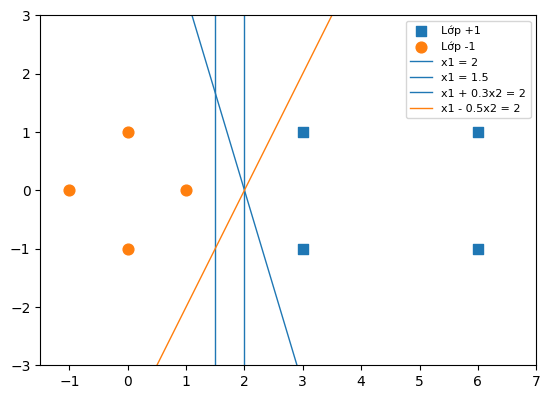

In [4]:
candidates = {'x1 = 2        ': (np.array([1.0, 0.0]), -2.0),
              'x1 = 1.5      ': (np.array([1.0, 0.0]), -1.5),
              'x1 + 0.3x2 = 2': (np.array([1.0, 0.3]), -2.0),
              'x1 - 0.5x2 = 2': (np.array([1.0, -0.5]), -2.0)}
x_line = np.linspace(-1.5, 7, 2)
plt.scatter(X[y == 1, 0], X[y == 1, 1], marker='s', s=60, label='Lớp +1')
plt.scatter(X[y == -1, 0], X[y == -1, 1], marker='o', s=60, label='Lớp -1')
for name, (w_c, b_c) in candidates.items():
    d = signed_distance(w_c, b_c, X, y)
    print('%s: phân loại đúng %d/8, lề = %.3f' % (name, (d > 0).sum(), d.min()))
    if w_c[1] == 0:
        plt.axvline(-b_c / w_c[0], lw=1, label=name.strip())
    else:
        plt.plot(x_line, -(w_c[0] * x_line + b_c) / w_c[1], lw=1, label=name.strip())
plt.xlim(-1.5, 7); plt.ylim(-3, 3); plt.legend(fontsize=8); plt.gca().set_aspect('equal')
plt.show()

Cả bốn siêu phẳng đều phân loại đúng, nhưng $x_1 = 2$ có lề lớn nhất. SVM chọn siêu phẳng có lề lớn nhất.